In [230]:
import pandas as pd
import copy,math
import numpy as np
import matplotlib.pyplot as plt

In [231]:
file = pd.read_csv("Housing.csv")

In [232]:

X = file.iloc[:, [1, 2, 3, 4, 10]].to_numpy(dtype=np.float64)
Y = file.iloc[:, 0].to_numpy(dtype=np.float64)

In [233]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("X_test :", X_test.shape)

X_test : (109, 5)


In [234]:
b_init = 4706324.20
w_init = np.array([679784.16108007,113853.85524508,564996.83769347,423850.53400103,288572.51539751])
print(f"w_init shape: {w_init.shape}, b_init type: {type(b_init)}")

w_init shape: (5,), b_init type: <class 'float'>


In [235]:
import numpy as np

def zscore_normalize_features(X):
    # 1. Find the mean of each feature column
    mu = np.mean(X, axis=0)
    sigma = np.std(X, axis=0)                 
    # 3. Apply the formula: (X - mean) / std_deviation
    X_norm = (X - mu) / sigma                   
    
    return X_norm, mu, sigma


In [236]:
# Scale x_train
x_train_scaled, x_mean, x_std = zscore_normalize_features(X_train)

# Let's peek at the first row to see the difference!
print(f"Original first row: {X_train[0, :]}")
print(f"Scaled first row:   {x_train_scaled[0, :]}")
print("X_train_scaled :", x_train_scaled.shape)

Original first row: [6.e+03 3.e+00 2.e+00 4.e+00 1.e+00]
Scaled first row:   [0.38416819 0.05527092 1.53917323 2.58764353 0.36795665]
X_train_scaled : (436, 5)


In [237]:
# Scale x_train
x_test_scaled, x_mean_test, x_std_test = zscore_normalize_features(X_test)
# Let's peek at the first row to see the difference!
print(f"Original first row: {X_test[0, :]}")
print(f"Scaled first row:   {X_test_scaled[0, :]}")
print("X_test :", x_test_scaled.shape)

Original first row: [5.9e+03 4.0e+00 2.0e+00 2.0e+00 1.0e+00]
Scaled first row:   [0.38416819 0.05527092 1.53917323 2.58764353 0.36795665]
X_test : (109, 5)


In [238]:
def predict(x, w, b): 
    """
    single predict using linear regression
    Args:
      x (ndarray): Shape (n,) example with multiple features
      w (ndarray): Shape (n,) model parameters   
      b (scalar):             model parameter 
      
    Returns:
      p (scalar):  prediction
    """
    return np.dot(x, w) + b     

In [239]:
# get a row from our training data
x_vec = x_train_scaled[4,:]
print(f"x_vec shape {x_vec.shape}, x_vec value: {x_vec}")

# make a prediction
f_wb = predict(x_vec,w_init, b_init)
print(f"f_wb shape , prediction: {f_wb}")

x_vec shape (5,), x_vec value: [-0.63773026  0.05527092 -0.5579503   0.25421524 -0.80305867]
f_wb shape , prediction: 3839866.5282800673


In [240]:
def compute_cost(X, y, w, b): 
    """
    compute cost
    Args:
      X (ndarray (m,n)): Data, m examples with n features
      y (ndarray (m,)) : target values
      w (ndarray (n,)) : model parameters  
      b (scalar)       : model parameter
      
    Returns:
      cost (scalar): cost
    """
    m = X.shape[0]
    cost = 0.0
    for i in range(m):                                
        f_wb_i = np.dot(X[i], w) + b           #(n,)(n,) = scalar (see np.dot)
        cost = cost + (f_wb_i - y[i])**2       #scalar
    cost = cost / (2 * m)                      #scalar    
    return cost

In [241]:
# Compute and display cost using our pre-chosen optimal parameters. 
cost = compute_cost(x_train_scaled, y_train, w_init, b_init)
print(f'Cost at optimal w : {cost}')

Cost at optimal w : 675004510848.2074


In [242]:
def compute_gradient(X, y, w, b): 
    """
    Computes the gradient for linear regression 
    Args:
      X (ndarray (m,n)): Data, m examples with n features
      y (ndarray (m,)) : target values
      w (ndarray (n,)) : model parameters  
      b (scalar)       : model parameter
      
    Returns:
      dj_dw (ndarray (n,)): The gradient of the cost w.r.t. the parameters w. 
      dj_db (scalar):       The gradient of the cost w.r.t. the parameter b. 
    """
    m,n = X.shape           #(number of examples, number of features)
    dj_dw = np.zeros((n,))
    dj_db = 0.

    for i in range(m):                             
        err = (np.dot(X[i], w) + b) - y[i]   
        for j in range(n):                         
            dj_dw[j] = dj_dw[j] + err * X[i, j]    
        dj_db = dj_db + err                        
    dj_dw = dj_dw / m                                
    dj_db = dj_db / m                                
        
    return dj_db, dj_dw

In [243]:
tmp_dj_db, tmp_dj_dw = compute_gradient(x_train_scaled, y_train, w_init, b_init)
print(f'dj_db at initial w,b: {tmp_dj_db}')
print(f'dj_dw at initial w,b: \n {tmp_dj_dw}')

dj_db at initial w,b: -203.18532110053573
dj_dw at initial w,b: 
 [-180.11863732  504.42589081 -237.5192393  -285.56268241  150.37125183]


In [244]:
def gradient_descent(X, y, w_in, b_in, cost_function, gradient_function, alpha, num_iters): 
    """
    Performs batch gradient descent to learn theta. Updates theta by taking 
    num_iters gradient steps with learning rate alpha
    
    Args:
      X (ndarray (m,n))   : Data, m examples with n features
      y (ndarray (m,))    : target values
      w_in (ndarray (n,)) : initial model parameters  
      b_in (scalar)       : initial model parameter
      cost_function       : function to compute cost
      gradient_function   : function to compute the gradient
      alpha (float)       : Learning rate
      num_iters (int)     : number of iterations to run gradient descent
      
    Returns:
      w (ndarray (n,)) : Updated values of parameters 
      b (scalar)       : Updated value of parameter 
      """
    
    # An array to store cost J and w's at each iteration primarily for graphing later
    J_history = []
    w = copy.deepcopy(w_in)  #avoid modifying global w within function
    b = b_in
    
    for i in range(num_iters):

        # Calculate the gradient and update the parameters
        dj_db,dj_dw = gradient_function(X, y, w, b)   ##None

        # Update Parameters using w, b, alpha and gradient
        w = w - alpha * dj_dw               ##None
        b = b - alpha * dj_db               ##None
      
        # Save cost J at each iteration
        if i<100000:      # prevent resource exhaustion 
            J_history.append( cost_function(X, y, w, b))

        # Print cost every at intervals 10 times or as many iterations if < 10
        if i% math.ceil(num_iters / 10) == 0:
            print(f"Iteration {i:4d}: Cost {J_history[-1]:8.2f}   ")
        
    return w, b, J_history #return final w,b and J history for graphing

In [245]:
# initialize parameters
initial_w = np.zeros_like(w_init)
initial_b = 0.
# some gradient descent settings
iterations = 1000
alpha = 5.0e-7
# run gradient descent 
w_final, b_final, J_hist = gradient_descent(x_train_scaled, y_train, initial_w, initial_b,
                                                    compute_cost, compute_gradient, 
                                                    alpha, iterations)
print(f"b,w found by gradient descent: {b_final:0.2f},{w_final} ")
m,_ = x_train.shape
for i in range(m):
    print(f"prediction: {np.dot(x_train_scaled[i], w_final) + b_final:0.2f}, target value: {y_train[i]}")

Iteration    0: Cost 12617383564370.16   
Iteration  100: Cost 12616119747744.06   
Iteration  200: Cost 12614856071180.45   
Iteration  300: Cost 12613592534662.59   
Iteration  400: Cost 12612329138173.89   
Iteration  500: Cost 12611065881697.65   
Iteration  600: Cost 12609802765217.26   
Iteration  700: Cost 12608539788716.04   
Iteration  800: Cost 12607276952177.36   
Iteration  900: Cost 12606014255584.56   
b,w found by gradient descent: 2352.68,[468.49551295 325.90166484 467.31806588 355.4271847  332.32821921] 
prediction: 4311.95, target value: 7525000.0
prediction: 4101.57, target value: 6300000.0
prediction: 1576.02, target value: 3920000.0
prediction: 1392.08, target value: 3430000.0
prediction: 1634.65, target value: 3010000.0
prediction: 1902.75, target value: 4620000.0
prediction: 1655.93, target value: 1750000.0
prediction: 1502.12, target value: 3010000.0
prediction: 1098.68, target value: 2520000.0
prediction: 1702.98, target value: 3710000.0
prediction: 1500.60, ta

In [246]:
# Reset your parameters to zeros or small values
initial_w = np.zeros(x_train_scaled.shape[1])
initial_b = 0.0

# Settings for scaled data
iterations = 1000
alpha = 0.01  # A healthy, robust learning rate!

# Run gradient descent using x_train_scaled
w_final, b_final, J_hist = gradient_descent(x_train_scaled, y_train, initial_w, initial_b,
                                            compute_cost, compute_gradient,
                                            alpha, iterations)

print(f"\nFinal b: {b_final:0.2f}")
print(f"Final w vector: {w_final}")


Iteration    0: Cost 12366019452573.64   
Iteration  100: Cost 2165251238323.05   
Iteration  200: Cost 875553213629.56   
Iteration  300: Cost 702650179179.18   
Iteration  400: Cost 678956518700.92   
Iteration  500: Cost 675609906942.87   
Iteration  600: Cost 675108684965.14   
Iteration  700: Cost 675025333907.25   
Iteration  800: Cost 675009183204.11   
Iteration  900: Cost 675005479710.54   

Final b: 4706324.20
Final w vector: [679784.16108007 113853.85524508 564996.83769347 423850.53400103
 288572.51539751]


In [257]:
y_pred = np.dot(x_test_scaled, w_final) + b_final

In [258]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 1144483.379064786
RMSE: 1540042.7327241097
R²  : 0.5307748229783831


In [260]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)
print("y_pred :", y_pred.shape)
print("X_test_scaled :", x_test_scaled.shape)

X_train: (436, 5)
X_test : (109, 5)
y_train: (436,)
y_test : (109,)
y_pred : (109,)
X_test_scaled : (109, 5)


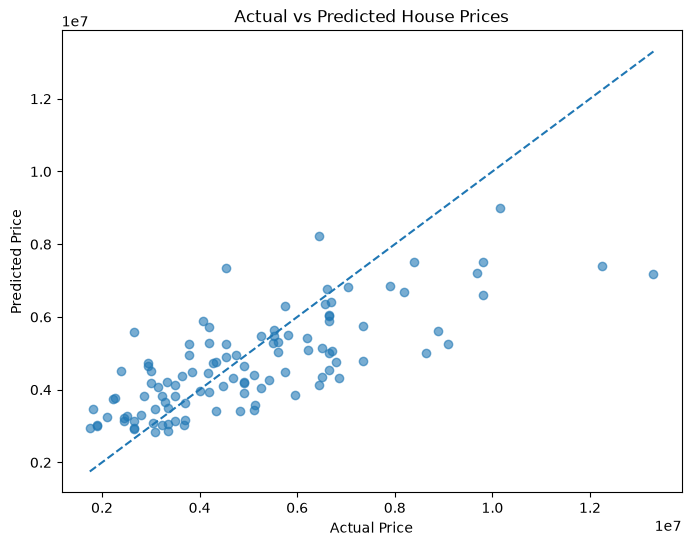

In [261]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")

plt.show()